# Setup

In [1]:
import sys
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
# Importante: questa riga deve essere PRIMA di "import torch"
# # Detect environment
# IN_COLAB = 'google.colab' in sys.modules
#try:
#    import google.colab
#    IN_COLAB = True
#except ImportError:
#    IN_COLAB = False
IN_COLAB = False
print(f"[INFO] Environment: {'Google Colab' if IN_COLAB else 'Local'}")

#  Mount Drive (Colab only) 
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/CV-project-25-26'
    
    # Add project to path so src.* imports work
    if PROJECT_ROOT not in sys.path:
        sys.path.insert(0, PROJECT_ROOT)
    os.chdir(PROJECT_ROOT)
    print(f"[INFO] CWD: {os.getcwd()}")

# ── Install dependencies ──────────────────────────────────────
# Uncomment only the first time (Colab) or if the local env
# doesn't have all packages yet.
#
# !pip install -q lightning einops torchvision lejepa
#
# If lejepa is not on PyPI, clone the repo and install locally:
# !git clone https://github.com/<lejepa-repo> /content/lejepa
# !pip install -q -e /content/lejepa

# Verify GPU 
import torch

print(f"[INFO] PyTorch  : {torch.__version__}")
print(f"[INFO] CUDA     : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"[INFO] GPU      : {torch.cuda.get_device_name(0)}")
    print(f"[INFO] VRAM     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

torch.set_float32_matmul_precision('high')
print("[INFO] float32 matmul precision -> high")


[INFO] Environment: Local
[INFO] PyTorch  : 2.12.0.dev20260408+cu128
[INFO] CUDA     : True
[INFO] GPU      : NVIDIA GeForce RTX 5070 Laptop GPU
[INFO] VRAM     : 8.5 GB
[INFO] float32 matmul precision -> high


# Imports & Config

In [2]:
import gc
import time
from pathlib import Path

import lightning as L
from lightning.pytorch.loggers import CSVLogger
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor

# Project modules 
import src.config as cfg
from src.config import (
    DEVICE, ARCH_TYPE,
    SSL_BATCH_SIZE, FT_BATCH_SIZE, LEARNING_RATE, WEIGHT_DECAY,
    EPOCHS_PRETRAIN, EPOCHS_FINETUNE,
    SSL_LR, SSL_WEIGHT_DECAY, SSL_PROJ_DIM, SSL_NUM_SLICES, SSL_LAMB,
    LAMBDA_1, LAMBDA_2, LAMBDA_3,
    DATASET_NYU_PATH, DATASET_KITTI_PATH, DATASET_KITTI_PATH_GT,
    MODEL_SAVE_PATH, SSL_CKPT_PATH, FINETUNE_CKPT_PATH,
    OUTPUT_DIR, IMAGES_DIR, JSON_DIR,
)
from src.network    import METERModel
from src.dataset    import NYUDataset, KITTIDataset, build_dataloader
from src.evaluation import (
    evaluate_depth_model,
    geometric_probing_pca,
    geometric_probing_test_set,
)
from src.utils import Timer, save_checkpoint, load_checkpoint, log_metrics_to_csv
from src.train  import LeJEPAMeter, METERFinetune, get_callbacks

# Configuration summary 
print("=" * 55)
print("  METER + LeJEPA — Project 7 Configuration")
print("=" * 55)
print(f"  Device          : {DEVICE}")
print(f"  Architecture    : METER-{ARCH_TYPE.upper()}")
print()
print("  [Pre-training — LeJEPA SSL]")
print(f"    Epochs        : {EPOCHS_PRETRAIN}")
print(f"    LR            : {SSL_LR}")
print(f"    Weight decay  : {SSL_WEIGHT_DECAY}")
print(f"    Proj dim      : {SSL_PROJ_DIM}")
print(f"    SIGReg slices : {SSL_NUM_SLICES}")
print(f"    Lambda (SIG)  : {SSL_LAMB}")
print()
print("  [Fine-tuning — Supervised MDE  (paper Sec. IV-A)]")
print(f"    Epochs        : {EPOCHS_FINETUNE}")
print(f"    Batch size SSL: {SSL_BATCH_SIZE}")
print(f"    Batch size FT : {FT_BATCH_SIZE}")
print(f"    LR            : {LEARNING_RATE}   (AdamW, StepLR /10 every 20 ep.)")
print(f"    Weight decay  : {WEIGHT_DECAY}")
print(f"    λ1 (grad)     : {LAMBDA_1}")
print(f"    λ2 (normal)   : {LAMBDA_2}")
print(f"    λ3 (ssim)     : {LAMBDA_3}")
print()
print("  [Paths]")
print(f"    NYU           : {DATASET_NYU_PATH}")
print(f"    KITTI RGB     : {DATASET_KITTI_PATH}")
print(f"    KITTI GT      : {DATASET_KITTI_PATH_GT}")
print(f"    Checkpoints   : {MODEL_SAVE_PATH}")
print("=" * 55)

# Reproducibility seed 
L.seed_everything(42, workers=True)
print("[INFO] Global seed → 42")

W0601 21:10:10.013000 19308 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
Seed set to 42


  METER + LeJEPA — Project 7 Configuration
  Device          : cuda
  Architecture    : METER-XS

  [Pre-training — LeJEPA SSL]
    Epochs        : 50
    LR            : 0.0005
    Weight decay  : 0.05
    Proj dim      : 64
    SIGReg slices : 256
    Lambda (SIG)  : 0.05

  [Fine-tuning — Supervised MDE  (paper Sec. IV-A)]
    Epochs        : 60
    Batch size SSL: 32
    Batch size FT : 64
    LR            : 0.001   (AdamW, StepLR /10 every 20 ep.)
    Weight decay  : 0.01
    λ1 (grad)     : 0.5
    λ2 (normal)   : 100
    λ3 (ssim)     : 100

  [Paths]
    NYU           : C:\Users\andre\Desktop\CV-project-25-26\data\raw\nyu
    KITTI RGB     : C:\Users\andre\Desktop\CV-project-25-26\data\raw\kitti
    KITTI GT      : C:\Users\andre\Desktop\CV-project-25-26\data\raw\kitti
    Checkpoints   : C:\Users\andre\Desktop\CV-project-25-26\models\checkpoints
[INFO] Global seed → 42


# Dataset

In [3]:
# Select fine-tuning dataset 
# Options: "nyu" | "kitti" | "both"
DATASET_NAME = "nyu" 
FT_BATCH = 16 if DATASET_NAME == "kitti" else FT_BATCH_SIZE


print(f"\n[INFO] Selected dataset: {DATASET_NAME.upper()}")

# ------------------------------------------------------------
# 3A — SSL Pre-training DataLoader  (in-domain per dataset)
# ------------------------------------------------------------
if DATASET_NAME == "nyu":
    print("\n[STEP 3A] SSL DataLoader (NYU raw — pretrain mode)")
    _full_ssl = NYUDataset(
        path   = DATASET_NYU_PATH,
        mode   = "pretrain",
        split  = "train",
        kaggle = False,
    )
    from torch.utils.data import random_split
    _gen = torch.Generator().manual_seed(42)
    _n_total = len(_full_ssl)
    _n_val   = max(1, int(0.1 * _n_total))
    _n_train = _n_total - _n_val
    ssl_dataset, ssl_val_dataset = random_split(
        _full_ssl, [_n_train, _n_val], generator=_gen
    )
    print(f"[INFO] SSL split — train: {_n_train:,}  val: {_n_val:,}")
elif DATASET_NAME == "kitti":
    print("\n[STEP 3A] SSL DataLoader (KITTI raw — pretrain mode)")
    kitti_rgb_root = DATASET_KITTI_PATH / "rgb"
    _full_kitti_ssl = KITTIDataset(
        path  = kitti_rgb_root,
        mode  = "pretrain",
        split = "all",
    )
    # Subset random del train: SSL non ha bisogno di tutti i 163k sample
    from torch.utils.data import Subset
    import random as _r
    _r.seed(42)
    _train_ids = _r.sample(range(len(_full_kitti_ssl)), k=10000)
    ssl_dataset = Subset(_full_kitti_ssl, _train_ids)
    print(f"[INFO] SSL train subset: {len(ssl_dataset):,} samples (from {len(_full_kitti_ssl):,} total)")
    # Use the same KITTI raw as val (SSL is self-supervised, no labels needed)
    ssl_val_dataset = KITTIDataset(
        path  = kitti_rgb_root,
        mode  = "pretrain",
        split = "all",
    )
    from torch.utils.data import Subset
    import random as _r
    _r.seed(42)
    _val_ids = _r.sample(range(len(_full_kitti_ssl)), k=2000) 
    ssl_val_dataset = Subset(_full_kitti_ssl, _val_ids)
else:
    raise ValueError(f"DATASET_NAME must be 'nyu' or 'kitti' for SSL, got '{DATASET_NAME}'")

ssl_loader     = build_dataloader(ssl_dataset,     batch_size=SSL_BATCH_SIZE, shuffle=True,  drop_last=True)
ssl_val_loader = build_dataloader(ssl_val_dataset, batch_size=SSL_BATCH_SIZE, shuffle=False, drop_last=True) 
print(f"[INFO] SSL dataset  : {len(ssl_dataset):,} samples")
print(f"[INFO] SSL batches  : {len(ssl_loader):,}")
print(f"[INFO] SSL val      : {len(ssl_val_dataset):,} samples")

# ------------------------------------------------------------
# 3B — Fine-tuning DataLoaders
# ------------------------------------------------------------

if DATASET_NAME in ("nyu", "both"):
    print("\n[STEP 3B] NYU Fine-tuning DataLoaders")

    # Train: 50K subset — paper Section IV-B
    nyu_train = NYUDataset(
        path   = DATASET_NYU_PATH,
        mode   = "finetune",
        split  = "train",
        kaggle = False,
    )
    # Test: 654 pairs from the official .mat — paper Section IV-B
    nyu_test = NYUDataset(
        path   = DATASET_NYU_PATH,
        mode   = "finetune",
        split  = "test",
        kaggle = False,
    )
    # Sanity check: paper uses ~50K train samples (Section IV-B).
    # If you are below ~40K you are likely on the .mat (795 samples) — fix the dataset path.
    n_train = len(nyu_train)
    print(f"[CHECK] NYU train samples: {n_train:,}")
    if n_train < 40000:
        print(f"[WARN] NYU train has only {n_train} samples — the paper uses ~50K.")
        print("[WARN] Expected if you are on the .mat (1449 total). Consider switching to "
              "Kaggle H5 (kaggle=True) or the 50K jpg/png pairs format to match the paper.")
    from src.utils import random_subset
    nyu_train_subset = random_subset(nyu_train, subset_size=10000, seed=42)
    nyu_train_loader = build_dataloader(nyu_train_subset, batch_size=FT_BATCH_SIZE, shuffle=True,  drop_last=True)
    nyu_test_loader  = build_dataloader(nyu_test,  batch_size=FT_BATCH_SIZE, shuffle=False)

    print(f"[INFO] NYU train    : {len(nyu_train_subset):,} samples  ({len(nyu_train_loader):,} batches)")
    print(f"[INFO] NYU test     : {len(nyu_test):,}  samples  ({len(nyu_test_loader):,}  batches)")

    # Sanity check: verify batch shape
    _rgb, _depth = next(iter(nyu_train_loader))
    print(f"[INFO] NYU batch    : RGB {tuple(_rgb.shape)}  Depth {tuple(_depth.shape)}")
    print(f"[INFO] Depth range  : [{_depth.min():.1f}, {_depth.max():.1f}] cm")
    assert _rgb.shape[1:] == (3, 192, 256),   f"Expected (3,192,256) — got {_rgb.shape[1:]}"
    assert _depth.shape[1:] == (1, 192, 256), f"Expected (1,192,256) — got {_depth.shape[1:]}"
    print("[OK] NYU shape verified")

if DATASET_NAME in ("kitti", "both"):
    print("\n[STEP 3B] KITTI Fine-tuning DataLoaders")

    # Expected structure by KITTIDataset (see dataset.py):
    #   path    = <kitti_root>/rgb/
    #   gt_root = <kitti_root>/depth/data_depth_annotated/
    kitti_rgb_root = DATASET_KITTI_PATH / "rgb"
    kitti_gt_root  = DATASET_KITTI_PATH_GT / "depth" 

    kitti_train = KITTIDataset(
        path     = kitti_rgb_root,
        gt_root  = kitti_gt_root,
        mode     = "finetune",
        split    = "train",
    )
    kitti_val = KITTIDataset(
        path     = kitti_rgb_root,
        gt_root  = kitti_gt_root,
        mode     = "finetune",
        split    = "val",
    )

    from src.utils import random_subset
    kitti_train_subset = random_subset(kitti_train, subset_size=10000, seed=42)
    kitti_train_loader = build_dataloader(kitti_train_subset, batch_size=FT_BATCH, shuffle=True,  drop_last=True)
    kitti_val_loader   = build_dataloader(kitti_val,   batch_size=FT_BATCH, shuffle=False)
    print(f"[INFO] KITTI train  : {len(kitti_train_subset):,} samples  ({len(kitti_train_loader):,} batches)")
    print(f"[INFO] KITTI val    : {len(kitti_val):,}  samples  ({len(kitti_val_loader):,}  batches)")

    # Sanity check
    _rgb_k, _depth_k = next(iter(kitti_train_loader))
    print(f"[INFO] KITTI batch  : RGB {tuple(_rgb_k.shape)}  Depth {tuple(_depth_k.shape)}")
    print(f"[INFO] Depth range  : [{_depth_k.min():.3f}, {_depth_k.max():.3f}] m")
    assert _rgb_k.shape[1:]   == (3, 192, 636), f"Expected (3,192,636) — got {_rgb_k.shape[1:]}"
    assert _depth_k.shape[1:] == (1, 192, 636), f"Expected (1,192,636) — got {_depth_k.shape[1:]}"
    print("[OK] KITTI shape verified")

print("\n[OK] Dataset ready")


[INFO] Selected dataset: NYU

[STEP 3A] SSL DataLoader (NYU raw — pretrain mode)

[INFO] NYUDataset — mode=pretrain, split=train, kaggle=False
[INFO] NYUDataset — 45827 samples  (format=rgb_only)
[INFO] SSL split — train: 41,245  val: 4,582
[INFO] DataLoader — batch=32  workers=4  shuffle=True  pin_memory=True
[INFO] DataLoader — batch=32  workers=4  shuffle=False  pin_memory=True
[INFO] SSL dataset  : 41,245 samples
[INFO] SSL batches  : 1,288
[INFO] SSL val      : 4,582 samples

[STEP 3B] NYU Fine-tuning DataLoaders

[INFO] NYUDataset — mode=finetune, split=train, kaggle=False
[INFO] NYUDataset — 45827 samples  (format=pairs)

[INFO] NYUDataset — mode=finetune, split=test, kaggle=False
[INFO] NYUDataset — 654 samples  (format=mat)
[CHECK] NYU train samples: 45,827
[INFO] DataLoader — batch=64  workers=4  shuffle=True  pin_memory=True
[INFO] DataLoader — batch=64  workers=4  shuffle=False  pin_memory=True
[INFO] NYU train    : 10,000 samples  (156 batches)
[INFO] NYU test     : 654  

# LeJEPA SSL Pre-training

[STEP 4A] Building LeJEPA model

[INFO] Initializing LeJEPA SSL model

[INFO] Building METER-xs
[INFO] Total params: 1,449,760
[INFO] Trainable params: 1,449,760
[INFO] Encoder dim: 192
[INFO] LeJEPA model ready


Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[INFO] Encoder output (emb)  : (2, 192) — expected (2, 192)
[INFO] Projector output (proj): (2, 64) — expected (2, 64)
[OK] Encoder → Projector: communication verified

[STEP 4D] Starting SSL pre-training — 50 epochs


c:\Users\andre\Desktop\CV-project-25-26\.venv\Lib\site-packages\torch\nn\modules\module.py:1369: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:39.)
  return t.to(
c:\Users\andre\Desktop\CV-project-25-26\.venv\Lib\site-packages\lightning\pytorch\utilities\model_summary\model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name       ┃ Type                  ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder    │ MobileViT             │  1.2 M │ train │     0 │
│ 1 │ global_aug │ Compose               │      0 │ train │     0 │
│ 2 │ local_aug  │ Compose               │      0 │ train │     0 │
│ 3 │ projector  │ MLP                   │  215 K │ train │     0 │
│ 4 │ sigreg     │ SlicingUnivariateTest │      0 │ train │     0 │
└───┴────────────┴───────────────────────┴────────┴───────┴───────┘

Trainable params: 1.4 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.4 M                                                                                                
Total estimated model params size (MB): 5                                                                          
Modules in train mode: 221                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

c:\Users\andre\Desktop\CV-project-25-26\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

`Trainer.fit` stopped: `max_epochs=50` reached.


[INFO] Pre-training completed in 792m 52s
[INFO] SSL checkpoint → C:\Users\andre\Desktop\CV-project-25-26\models\checkpoints\ssl_nyu\last.ckpt

[STEP 4E] Zero-shot Geometric Probing (PCA)

[INFO] Running test-set probing (4 samples)
[INFO] Saved: C:\Users\andre\Desktop\CV-project-25-26\output\images\pca_ssl_encoder.png


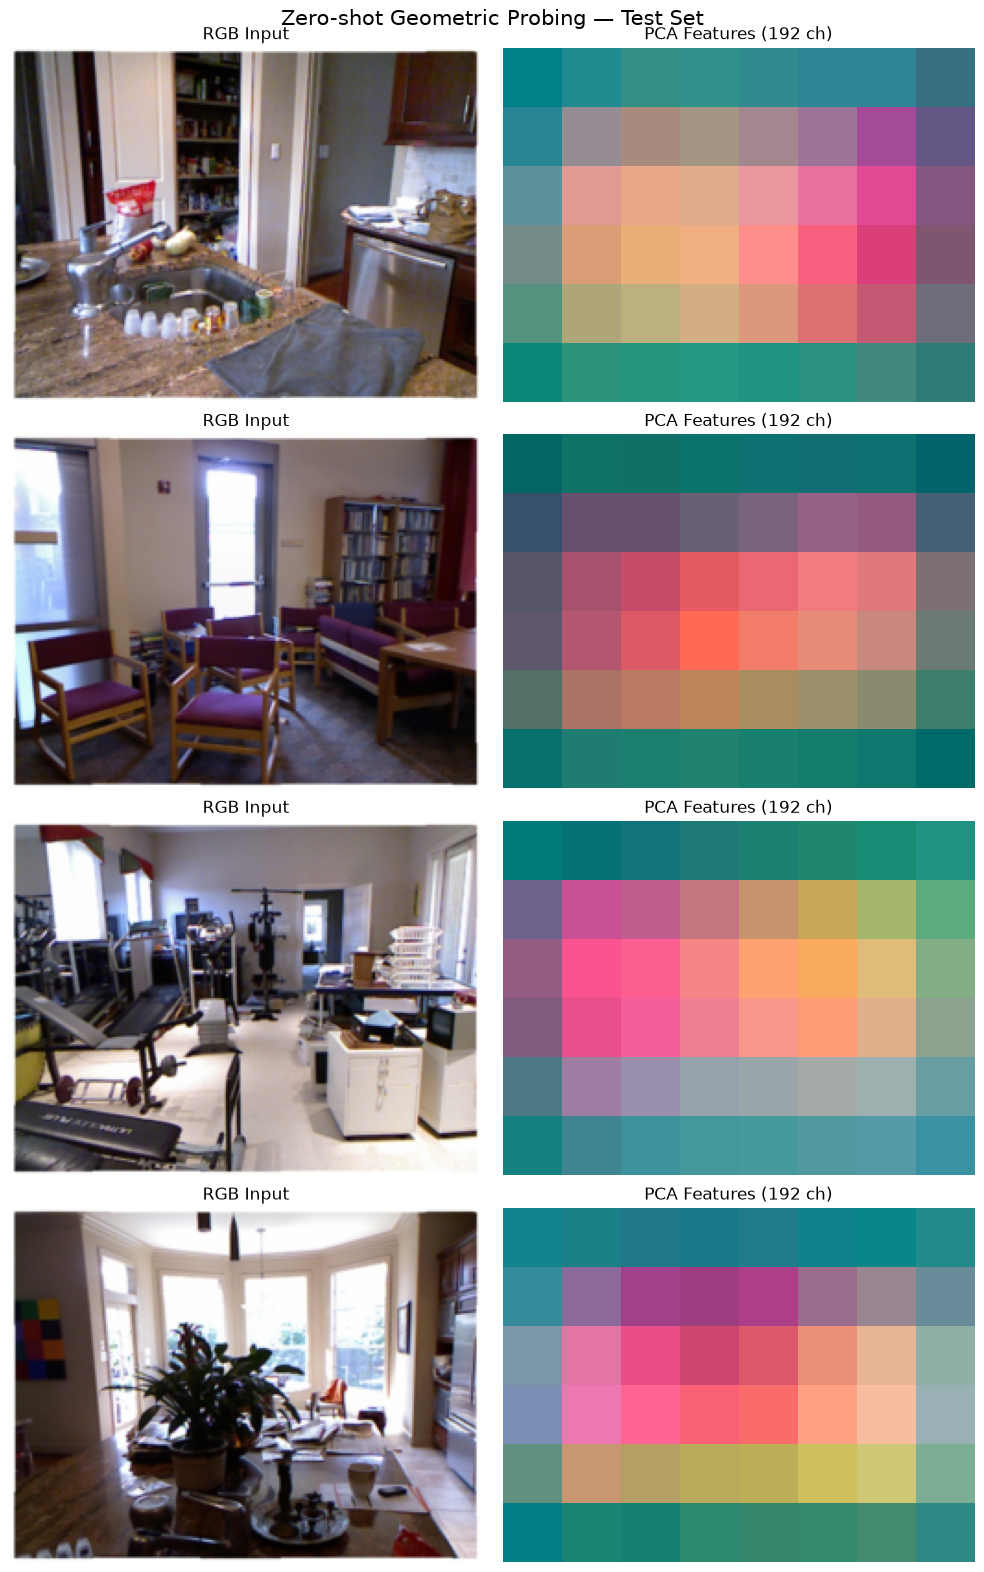

[OK] SSL probing completed


In [4]:
# Parameters (override config.py if different)
SSL_ARCH           = ARCH_TYPE          # "xxs" | "xs" | "s"
SSL_EPOCHS         = EPOCHS_PRETRAIN    # 50
SSL_BATCH          = SSL_BATCH_SIZE     # 16
SKIP_PRETRAIN      = False              # True → skip, load existing ckpt

ssl_ckpt_dir = MODEL_SAVE_PATH / f"ssl_{DATASET_NAME}"
ssl_ckpt_dir.mkdir(parents=True, exist_ok=True)

# 4A: LeJEPA Model 
print("[STEP 4A] Building LeJEPA model")
ssl_model = LeJEPAMeter(
    arch_type     = SSL_ARCH,
    proj_dim      = SSL_PROJ_DIM,
    num_slices    = SSL_NUM_SLICES,
    lamb          = SSL_LAMB,
    lr            = SSL_LR,
    weight_decay  = SSL_WEIGHT_DECAY,
    warmup_epochs = 10,
    dataset       = DATASET_NAME,
)

# Verify encoder → projector communication
# MobileViT encoder returns (features, [y0, y1, y2, y3])
# LeJEPAMeter does: features, _ = encoder(x) → emb = features.mean([-2,-1])
_dummy = torch.randn(2, 3, 256, 256)
_emb, _proj = ssl_model(_dummy)
print(f"[INFO] Encoder output (emb)  : {tuple(_emb.shape)} — expected (2, {cfg.ENC_DIMS.get(SSL_ARCH, '?')})")
print(f"[INFO] Projector output (proj): {tuple(_proj.shape)} — expected (2, {SSL_PROJ_DIM})")
assert _proj.shape == (2, SSL_PROJ_DIM), "Projector shape mismatch!"
print("[OK] Encoder → Projector: communication verified")

# 4B: Callbacks and Logger 
ssl_callbacks = [
    ModelCheckpoint(
        dirpath   = str(ssl_ckpt_dir),
        filename  = "ssl-{epoch:02d}-{val/loss:.4f}",
        monitor   = "val/loss",
        mode      = "min",
        save_top_k = 1,
        save_last  = True,
    ),
    # EarlyStopping(
    #    monitor  = "val/loss",
    #    patience = 10,
    #    mode     = "min",
    #    strict   = False,
    #),
    LearningRateMonitor(logging_interval="epoch"),
]
ssl_logger = CSVLogger(save_dir=str(OUTPUT_DIR), name="ssl_log")

# 4C: Trainer 
ssl_trainer = L.Trainer(
    max_epochs         = SSL_EPOCHS,
    accelerator        = "auto",
    devices            = 1,
    precision="16-mixed",
    gradient_clip_val       = 1.0,        
    gradient_clip_algorithm = "norm",
    callbacks          = ssl_callbacks,
    logger             = ssl_logger,
    log_every_n_steps  = 10,
    enable_progress_bar = True,
    accumulate_grad_batches = 1,         # fix SIGReg covariance instability
)

# 4D: Training 
if SKIP_PRETRAIN:
    print("[INFO] SKIP_PRETRAIN=True — loading existing checkpoint")
    _ckpt = str(ssl_ckpt_dir / "last.ckpt")
    if not Path(_ckpt).exists():
        print("[WARN] No SSL checkpoint found — fine-tuning will start from scratch")
else:
    print(f"\n[STEP 4D] Starting SSL pre-training — {SSL_EPOCHS} epochs")
    _t = Timer()

    # Resume from checkpoint if it exists
    _last_ssl = ssl_ckpt_dir / "last.ckpt"
    ssl_trainer.fit(
        ssl_model,
        train_dataloaders = ssl_loader,
        val_dataloaders   = ssl_val_loader,
        ckpt_path         = str(_last_ssl) if _last_ssl.exists() else None,
    )
    print(f"[INFO] Pre-training completed in {_t.end()}")
    print(f"[INFO] SSL checkpoint → {ssl_ckpt_dir / 'last.ckpt'}")

# 4E: Zero-shot Geometric Probing 
print("\n[STEP 4E] Zero-shot Geometric Probing (PCA)")
_probe_loader = ssl_val_loader if DATASET_NAME == "nyu" else ssl_val_loader
geometric_probing_test_set(
    model       = ssl_model,
    device      = DEVICE,
    test_loader = _probe_loader,
    num_samples = 4,
    save_path   = str(IMAGES_DIR / "pca_ssl_encoder.png"),
)
print("[OK] SSL probing completed")

# Supervised Fine-tuning


[INFO] Initializing METERFinetune — dataset: nyu

[INFO] Building METER-xs
[INFO] Total params: 1,449,760
[INFO] Trainable params: 1,449,760
[LOAD] last.ckpt
       Loaded           : 250 layers
       Missing (rand)   : 0 layers
       Unexpected (skip): 0 layers
[INFO] SSL encoder loaded successfully from C:\Users\andre\Desktop\CV-project-25-26\models\checkpoints\ssl_nyu\last.ckpt
[INFO] METERFinetune ready
[INFO] Verifying encoder → decoder (skip connections)
  Encoder bottleneck : (1, 192, 6, 8)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



  Skip y0          : (1, 16, 96, 128)
  Skip y1          : (1, 48, 48, 64)
  Skip y2          : (1, 64, 24, 32)
  Skip y3          : (1, 80, 12, 16)
  Decoder output     : (1, 1, 48, 64) — expected (1, 1, 48, ...)
  Full model output  : (1, 1, 192, 256) — (after interpolate → 192×256)
[OK] Encoder → Decoder: communication verified
[INFO] NYU: EarlyStopping disabled, training for full max_epochs.

[STEP 5E] Starting METER-XS fine-tuning on NYU
  Epochs     : 60  (paper Section IV-A)
  Initial LR : 0.001  → /10 at epochs 20, 40
  Loss       : L_depth + 0.5*L_grad + 100*L_norm + 100*L_SSIM
[INFO] Optimizer — encoder LR mult: 0.1 (pretrained=True)


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type                   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ METERModel             │  1.4 M │ train │     0 │
│ 1 │ loss_fn │ balanced_loss_function │     18 │ train │     0 │
└───┴─────────┴────────────────────────┴────────┴───────┴───────┘

Trainable params: 1.4 M                                                                                            
Non-trainable params: 18                                                                                           
Total params: 1.4 M                                                                                                
Total estimated model params size (MB): 5                                                                          
Modules in train mode: 235                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

... (4 outputs left out)

[INFO] Fine-tuning completed in 91m 24s

[STEP 5F] Final test on NYU


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│     test/abs_rel_nyu      │    0.1920735388994217     │
│      test/delta1_nyu      │    0.6963832974433899     │
│      test/grad_epoch      │    28.478769302368164     │
│       test/l1_epoch       │     57.1324348449707      │
│        test/l1_nyu        │     57.1324462890625      │
│      test/loss_epoch      │    151.65367126464844     │
│     test/normal_epoch     │     56.07755661010742     │
│       test/rmse_nyu       │    0.7902048826217651     │
│      test/ssim_epoch      │     9.964914321899414     │
└───────────────────────────┴───────────────────────────┘


[STEP 5G] Post fine-tuning Geometric Probing

[INFO] Running test-set probing (4 samples)
[INFO] Saved: C:\Users\andre\Desktop\CV-project-25-26\output\images\pca_finetune_nyu.png


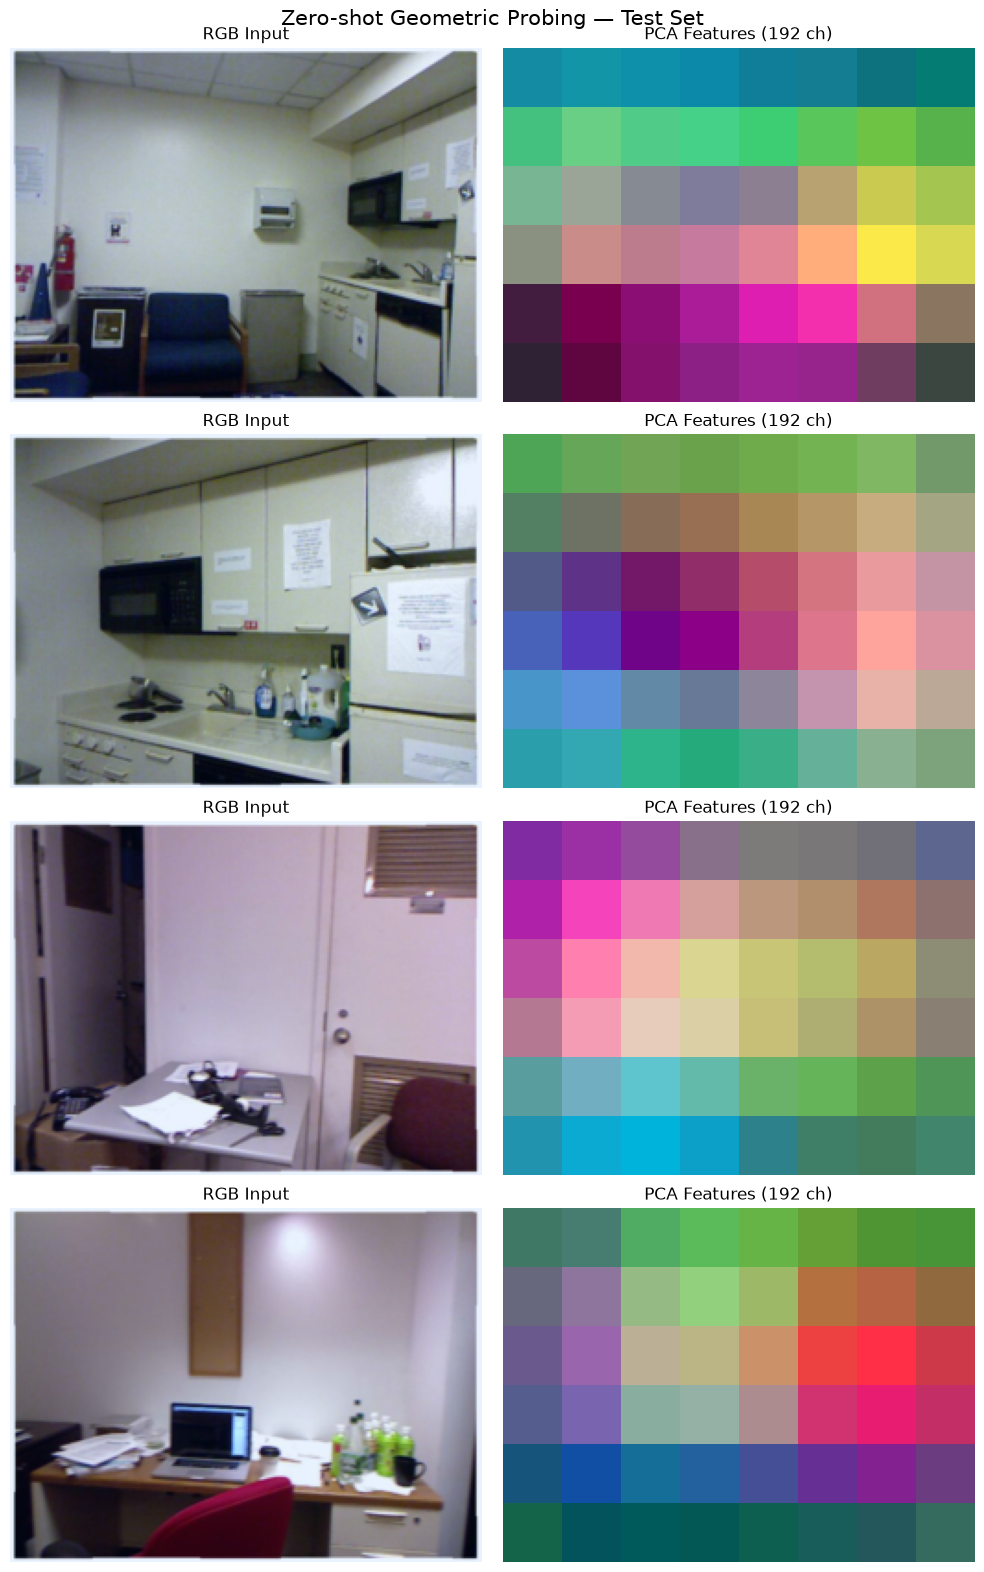

[OK] Fine-tuning probing completed
[INFO] JSON saved → C:\Users\andre\Desktop\CV-project-25-26\output\json\results_nyu_xs.json

  Pipeline completed.
  Checkpoint → C:\Users\andre\Desktop\CV-project-25-26\models\checkpoints\finetune_nyu
  Results    → C:\Users\andre\Desktop\CV-project-25-26\output\json
  Images     → C:\Users\andre\Desktop\CV-project-25-26\output\images


In [5]:
# Parameters
FT_ARCH          = ARCH_TYPE        # must match pre-training
FT_DATASET       = DATASET_NAME     # "nyu" | "kitti"
FT_EPOCHS        = EPOCHS_FINETUNE  # 60 — paper Section IV-A
FREEZE_ENCODER   = False            # True → train only decoder
USE_SSL_CKPT     = True             # True → load encoder from LeJEPA pre-training

ft_ckpt_dir = MODEL_SAVE_PATH / f"finetune_{FT_DATASET}"
ft_ckpt_dir.mkdir(parents=True, exist_ok=True)

# Path to SSL checkpoint for encoder loading
_ssl_ckpt_path = str(MODEL_SAVE_PATH / f"ssl_{DATASET_NAME}" / "last.ckpt") if USE_SSL_CKPT else None
if USE_SSL_CKPT and not Path(_ssl_ckpt_path).exists():
    print("[WARN] SSL checkpoint not found — fine-tuning will start from random weights")
    _ssl_ckpt_path = None

# 5A: Select train/val loaders
if FT_DATASET == "nyu":
    ft_train_loader = nyu_train_loader
    ft_val_loader   = nyu_test_loader
    val_monitor     = "val/rmse"
elif FT_DATASET == "kitti":
    ft_train_loader = kitti_train_loader
    ft_val_loader   = kitti_val_loader
    val_monitor     = "val/rmse"
else:
    raise ValueError(f"FT_DATASET must be 'nyu' or 'kitti', not '{FT_DATASET}'")

# 5B: METERFinetune Model
ft_lr = LEARNING_RATE # 1e-3 as in METER paper

ft_model = METERFinetune(
    arch_type       = FT_ARCH,
    lr              = ft_lr,
    weight_decay    = WEIGHT_DECAY,
    pretrained_ckpt = _ssl_ckpt_path,
    freeze_encoder  = False,
    dataset_name    = FT_DATASET,
)

# Verify encoder → decoder communication
# MobileViT.forward() → (bottleneck, [y0, y1, y2, y3])
# Decoder.forward(bottleneck, [y0, y1, y2, y3]) → depth map
print("[INFO] Verifying encoder → decoder (skip connections)")
_h, _w = (192, 256) if FT_DATASET == "nyu" else (192, 636)
_dummy_ft = torch.randn(1, 3, _h, _w)
_enc_out, _skips = ft_model.model.encoder(_dummy_ft)
print(f"  Encoder bottleneck : {tuple(_enc_out.shape)}")
for i, sk in enumerate(_skips):
    print(f"  Skip y{i}          : {tuple(sk.shape)}")
_dec_out = ft_model.model.decoder(_enc_out, _skips)
print(f"  Decoder output     : {tuple(_dec_out.shape)} — expected (1, 1, {_h//32 * 8}, ...)")
_full_out = ft_model(_dummy_ft)
print(f"  Full model output  : {tuple(_full_out.shape)} — (after interpolate → {_h}×{_w})")
assert _full_out.shape == (1, 1, _h, _w), f"Output shape mismatch: {_full_out.shape}"
print("[OK] Encoder → Decoder: communication verified")

# 5C: Callbacks and Logger 
ft_callbacks = get_callbacks(
    save_dir     = str(ft_ckpt_dir),
    monitor      = val_monitor,
    dataset_name = FT_DATASET,
    arch_name    = FT_ARCH,
)
ft_logger = CSVLogger(save_dir=str(OUTPUT_DIR), name=f"finetune_{FT_DATASET}_log")

# 5D: Trainer
ft_trainer = L.Trainer(
    max_epochs              = FT_EPOCHS,
    accelerator             = "auto",
    devices                 = 1,
    precision               = "32",
    callbacks               = ft_callbacks,
    logger                  = ft_logger,
    log_every_n_steps       = 10,
    enable_progress_bar     = True,
    accumulate_grad_batches = 8 if FT_DATASET == "kitti" else 1,
    gradient_clip_val       = 5.0 if FT_DATASET == "kitti" else 1.0,
    gradient_clip_algorithm = "norm",
)

# 5E: Training
print(f"\n[STEP 5E] Starting METER-{FT_ARCH.upper()} fine-tuning on {FT_DATASET.upper()}")
print(f"  Epochs     : {FT_EPOCHS}  (paper Section IV-A)")
print(f"  Initial LR : {LEARNING_RATE}  → /10 at epochs 20, 40")
print(f"  Loss       : L_depth + {LAMBDA_1}*L_grad + {LAMBDA_2}*L_norm + {LAMBDA_3}*L_SSIM")

_t_ft = Timer()

# Resume from checkpoint if it exists
_last_ft = ft_ckpt_dir / "last.ckpt"
ft_trainer.fit(
    ft_model,
    train_dataloaders = ft_train_loader,
    val_dataloaders   = ft_val_loader,
    ckpt_path         = str(_last_ft) if _last_ft.exists() else None,
)
print(f"[INFO] Fine-tuning completed in {_t_ft.end()}")

# 5F: Final test
print(f"\n[STEP 5F] Final test on {FT_DATASET.upper()}")
ft_trainer.test(ft_model, dataloaders=ft_val_loader)

# 5G: Post fine-tuning PCA probing
print("\n[STEP 5G] Post fine-tuning Geometric Probing")
geometric_probing_test_set(
    model       = ft_model,
    device      = DEVICE,
    test_loader = ft_val_loader,
    num_samples = 4,
    save_path   = str(IMAGES_DIR / f"pca_finetune_{FT_DATASET}.png"),
)
print("[OK] Fine-tuning probing completed")

# Save final metrics to JSON
from src.utils import save_dict_to_json
_test_results = ft_trainer.logged_metrics
_out = {
    "arch"           : FT_ARCH,
    "dataset"        : FT_DATASET,
    "epochs"         : FT_EPOCHS,
    "ssl_pretrained" : USE_SSL_CKPT,
    "freeze_encoder" : FREEZE_ENCODER,
}
_out.update({k: float(v) for k, v in _test_results.items() if isinstance(v, torch.Tensor)})
save_dict_to_json(_out, JSON_DIR / f"results_{FT_DATASET}_{FT_ARCH}.json")

print("\n" + "=" * 55)
print("  Pipeline completed.")
print(f"  Checkpoint → {ft_ckpt_dir}")
print(f"  Results    → {JSON_DIR}")
print(f"  Images     → {IMAGES_DIR}")
print("=" * 55)

import gc
import torch
gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

# From-Scratch Baseline (no SSL pre-training)

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



[STEP 6B] Building from-scratch baseline (arch=xs, dataset=nyu)
[INFO] pretrained_ckpt=None  →  encoder RANDOMLY initialized

[INFO] Initializing METERFinetune — dataset: nyu

[INFO] Building METER-xs
[INFO] Total params: 1,449,760
[INFO] Trainable params: 1,449,760
[INFO] METERFinetune ready
[INFO] NYU: EarlyStopping disabled, training for full max_epochs.

[STEP 6E] Starting from-scratch baseline on NYU
  Epochs     : 60
  Initial LR : 0.001
  Loss       : L_depth + 0.5*L_grad + 100*L_norm + 100*L_SSIM
  Output dir : C:\Users\andre\Desktop\CV-project-25-26\models\checkpoints\finetune_from_scratch_nyu
[INFO] Optimizer — encoder LR mult: 1.0 (pretrained=False)


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type                   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ METERModel             │  1.4 M │ train │     0 │
│ 1 │ loss_fn │ balanced_loss_function │     18 │ train │     0 │
└───┴─────────┴────────────────────────┴────────┴───────┴───────┘

Trainable params: 1.4 M                                                                                            
Non-trainable params: 18                                                                                           
Total params: 1.4 M                                                                                                
Total estimated model params size (MB): 5                                                                          
Modules in train mode: 235                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

c:\Users\andre\Desktop\CV-project-25-26\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

... (3 outputs left out)

[INFO] From-scratch training completed in 88m 14s

[STEP 6F] Final test (baseline) on NYU


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│     test/abs_rel_nyu      │    0.19882073998451233    │
│      test/delta1_nyu      │     0.687889575958252     │
│      test/grad_epoch      │     28.15948486328125     │
│       test/l1_epoch       │      58.169677734375      │
│        test/l1_nyu        │     58.1696891784668      │
│      test/loss_epoch      │    152.25953674316406     │
│     test/normal_epoch     │    55.930965423583984     │
│       test/rmse_nyu       │    0.8081856369972229     │
│      test/ssim_epoch      │     9.999434471130371     │
└───────────────────────────┴───────────────────────────┘


[STEP 6G] Geometric Probing — from-scratch encoder

[INFO] Running test-set probing (4 samples)
[INFO] Saved: C:\Users\andre\Desktop\CV-project-25-26\output\images\pca_finetune_from_scratch_nyu.png


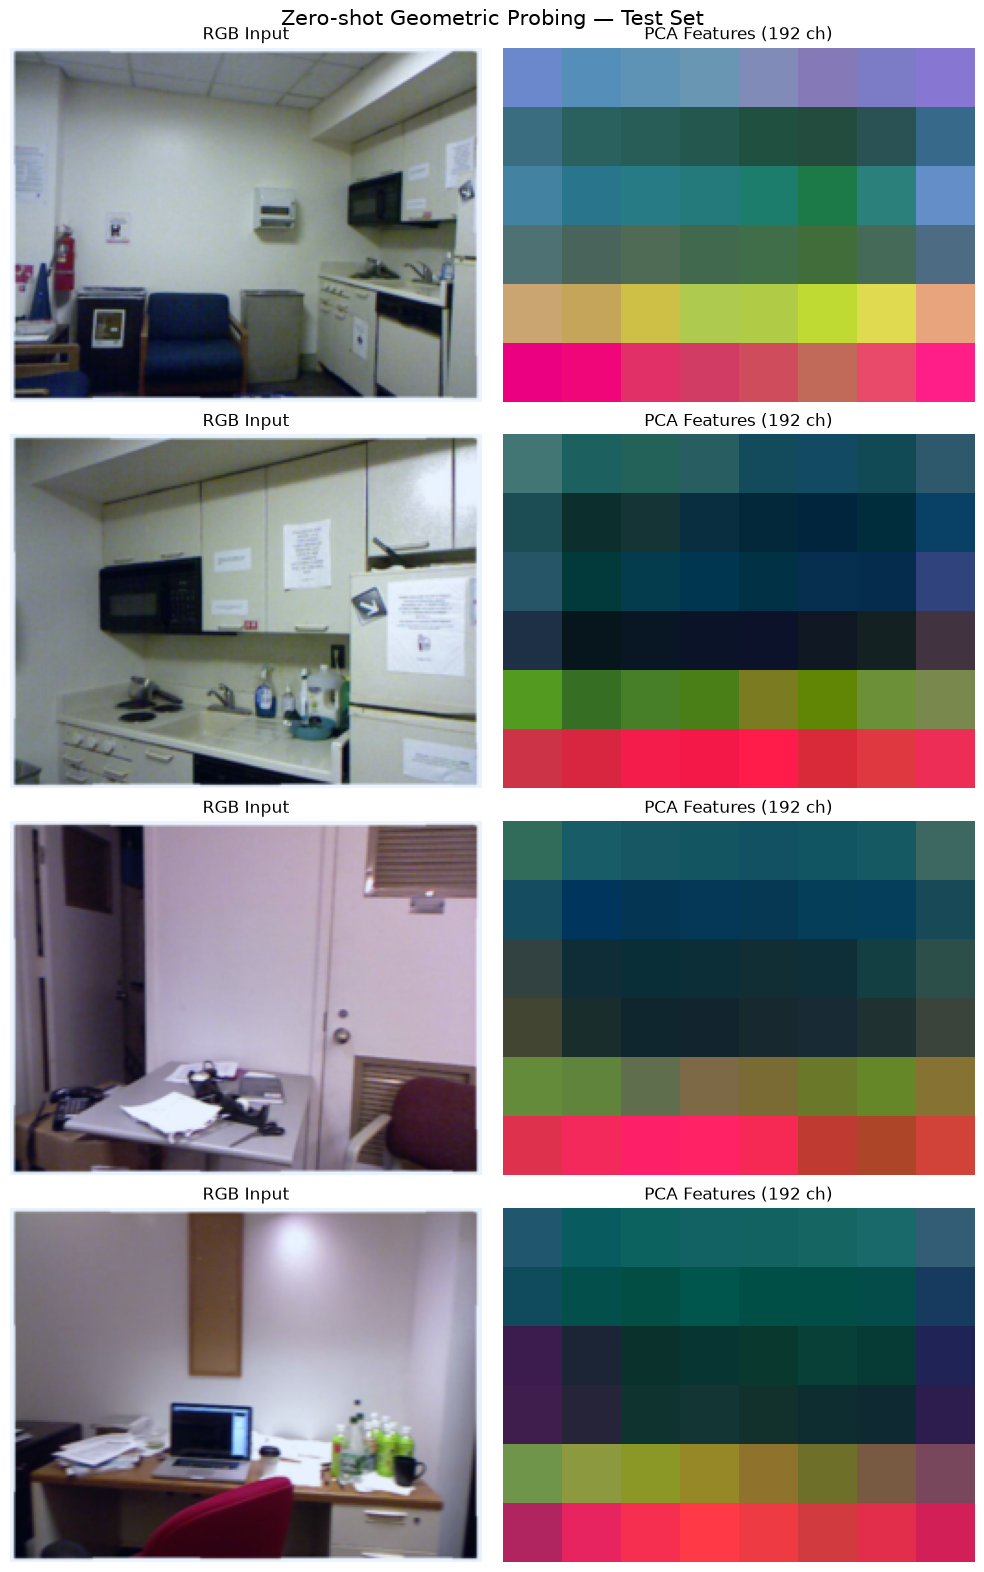

[OK] Baseline probing completed
[INFO] JSON saved → C:\Users\andre\Desktop\CV-project-25-26\output\json\results_from_scratch_main_nyu_xs.json

  Baseline (from-scratch) run completed.
  Checkpoint → C:\Users\andre\Desktop\CV-project-25-26\models\checkpoints\finetune_from_scratch_nyu
  Results    → C:\Users\andre\Desktop\CV-project-25-26\output\json\results_from_scratch_nyu_xs.json
  Images     → C:\Users\andre\Desktop\CV-project-25-26\output\images\pca_finetune_from_scratch_nyu.png


In [6]:
# Parameters
FT_ARCH          = ARCH_TYPE        # must match pre-training
FT_DATASET       = DATASET_NAME     # "nyu" | "kitti"
FT_EPOCHS        = EPOCHS_FINETUNE  # 60 — paper Section IV-A
FREEZE_ENCODER   = False            # True → train only decoder
USE_SSL_CKPT     = False            # False → do not load encoder from LeJEPA pre-training



L.seed_everything(42, workers=True)

fs_ckpt_dir = MODEL_SAVE_PATH / f"finetune_from_scratch_{FT_DATASET}"
fs_ckpt_dir.mkdir(parents=True, exist_ok=True)

# 6A
if FT_DATASET == "nyu":
    fs_train_loader, fs_val_loader = nyu_train_loader, nyu_test_loader
elif FT_DATASET == "kitti":
    fs_train_loader, fs_val_loader = kitti_train_loader, kitti_val_loader
else:
    raise ValueError(f"FT_DATASET must be 'nyu' or 'kitti', not '{FT_DATASET}'")
val_monitor = "val/rmse"

# 6B
print(f"\n[STEP 6B] Building from-scratch baseline (arch={FT_ARCH}, dataset={FT_DATASET})")
print("[INFO] pretrained_ckpt=None  →  encoder RANDOMLY initialized")
fs_lr = LEARNING_RATE # 1e-3 as in METER paper
fs_model = METERFinetune(
    arch_type       = FT_ARCH,
    lr              = fs_lr,
    weight_decay    = WEIGHT_DECAY,
    pretrained_ckpt = None, 
    freeze_encoder  = False,
    dataset_name    = FT_DATASET,
)

# 6C: Callbacks 
fs_callbacks = get_callbacks(
    save_dir     = str(fs_ckpt_dir),
    monitor      = val_monitor,
    dataset_name = FT_DATASET,
    arch_name    = FT_ARCH,
)
fs_logger = CSVLogger(save_dir=str(OUTPUT_DIR), name=f"finetune_from_scratch_{FT_DATASET}_log")

# 6D: Trainer 
fs_trainer = L.Trainer(
    max_epochs              = FT_EPOCHS,
    accelerator             = "auto",
    devices                 = 1,
    precision               = "32",
    callbacks               = fs_callbacks,
    logger                  = fs_logger,
    log_every_n_steps       = 10,
    enable_progress_bar     = True,
    accumulate_grad_batches = 8 if FT_DATASET == "kitti" else 1,
    gradient_clip_val       = 5.0 if FT_DATASET == "kitti" else 1.0,
    gradient_clip_algorithm = "norm",
)

# 6E: Training
print(f"\n[STEP 6E] Starting from-scratch baseline on {FT_DATASET.upper()}")
print(f"  Epochs     : {FT_EPOCHS}")
print(f"  Initial LR : {LEARNING_RATE}")
print(f"  Loss       : L_depth + {LAMBDA_1}*L_grad + {LAMBDA_2}*L_norm + {LAMBDA_3}*L_SSIM")
print(f"  Output dir : {fs_ckpt_dir}")

_t_fs = Timer()
_last_fs = fs_ckpt_dir / "last.ckpt"
fs_trainer.fit(
    fs_model,
    train_dataloaders = fs_train_loader,
    val_dataloaders   = fs_val_loader,
    ckpt_path         = str(_last_fs) if _last_fs.exists() else None,
)
print(f"[INFO] From-scratch training completed in {_t_fs.end()}")

# 6F: Final test
print(f"\n[STEP 6F] Final test (baseline) on {FT_DATASET.upper()}")
fs_trainer.test(fs_model, dataloaders=fs_val_loader)

# 6G: PCA probing 
print("\n[STEP 6G] Geometric Probing — from-scratch encoder")
geometric_probing_test_set(
    model       = fs_model,
    device      = DEVICE,
    test_loader = fs_val_loader,
    num_samples = 4,
    save_path   = str(IMAGES_DIR / f"pca_finetune_from_scratch_{FT_DATASET}.png"),
)
print("[OK] Baseline probing completed")

# 6H
from src.utils import save_dict_to_json
_test_results_fs = fs_trainer.logged_metrics
_out_fs = {
    "arch"           : FT_ARCH,
    "dataset"        : FT_DATASET,
    "epochs"         : FT_EPOCHS,
    "ssl_pretrained" : False,
    "freeze_encoder" : False,
    "variant"        : "from_scratch_baseline",
}
_out_fs.update({k: float(v) for k, v in _test_results_fs.items() if isinstance(v, torch.Tensor)})
save_dict_to_json(_out_fs, JSON_DIR / f"results_from_scratch_main_{FT_DATASET}_{FT_ARCH}.json")

print("\n" + "=" * 55)
print("  Baseline (from-scratch) run completed.")
print(f"  Checkpoint → {fs_ckpt_dir}")
print(f"  Results    → {JSON_DIR / f'results_from_scratch_{FT_DATASET}_{FT_ARCH}.json'}")
print(f"  Images     → {IMAGES_DIR / f'pca_finetune_from_scratch_{FT_DATASET}.png'}")
print("=" * 55)

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()